## What are the distribution statistics of the various cave passages?

In [ ]:
import numpy as np
from base.iterative_section_minimiser import mesh_intersect
import base.geometry as geom
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from base.utils import find_neighbours_with_knn, load_ply

from base.LBC_centreline import return_LBC_centreline
from base.refine_centreline import refine
from os.path import exists, normpath, join
from os import listdir

import geone
import cloudComPy as cc
from stl import mesh 

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
# change here the path to the repository of karst catalogue
data_repository = "F:/ScanLeica/data_paper/KarstConduitCatalogue" 

# list the different cave directories at the root directory level
caves = [elem for elem in listdir(data_repository) if "." not in elem]

# find unique passage filepaths
passages_fp = []
for cave in caves:
    # list all directory names within data
    new_passages = [elem for elem in listdir(join(data_repository, cave)) if "." not in elem]
    for new_passage in new_passages:
        passages_fp.append(normpath(join(data_repository, cave, new_passage, "mesh", f"{cave}_{new_passage}_mesh_5cm.ply")))

In [3]:
passages_fp

['F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\Archamps\\PostEtroiture\\mesh\\Archamps_PostEtroiture_mesh_5cm.ply',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\Archamps\\PreEtroiture\\mesh\\Archamps_PreEtroiture_mesh_5cm.ply',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\BaumeDeLongeaigue\\GrandToboggan\\mesh\\BaumeDeLongeaigue_GrandToboggan_mesh_5cm.ply',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CascadeDeMotiers\\MainGallery\\mesh\\CascadeDeMotiers_MainGallery_mesh_5cm.ply',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CocaliereCotepatiere\\AvenDeLaCocaliere1\\mesh\\CocaliereCotepatiere_AvenDeLaCocaliere1_mesh_5cm.ply',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CocaliereCotepatiere\\AvenDeLaCocaliere2\\mesh\\CocaliereCotepatiere_AvenDeLaCocaliere2_mesh_5cm.ply',
 'F:\\ScanLeica\\data_paper\\KarstConduitCatalogue\\CocaliereCotepatiere\\AvenDeLaCocaliere3\\mesh\\CocaliereCotepatiere_AvenDeLaCocaliere3_mesh_5cm.ply',
 'F:\\ScanLeica\\data_p

In [4]:
INDEX = 6
keepfile = True
if exists(passages_fp[INDEX][:-3]+"stl") and keepfile==True:
    # if there exists already a file in stl format.
    mesh_data = mesh.Mesh.from_file(passages_fp[INDEX][:-3]+"stl")
else:
    mesh_data = load_ply(passages_fp[INDEX])
    mesh_data.save(passages_fp[INDEX][:-3]+"stl")


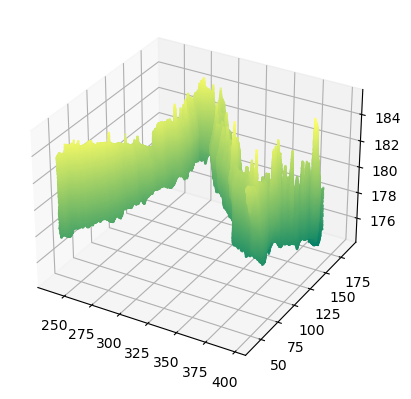

In [5]:
fig = plt.figure() 

ax = fig.add_subplot(projection="3d")

ax.scatter(*mesh_data.vectors[::50, 1, [0, 1, 2]].T, s=0.5, c = mesh_data.vectors[::50, 1, 2], cmap = "summer")

In [6]:
keep_triangles = True
adj_triangles_filepath = passages_fp[INDEX][:-4] + "_adjacent_triangles.txt"

if exists(adj_triangles_filepath) and keep_triangles == True:
    adj_triangles = np.loadtxt(adj_triangles_filepath)
else:
    adj_triangles = find_neighbours_with_knn(mesh_data)
    np.savetxt(adj_triangles_filepath, adj_triangles)

In [7]:
lbc_args = dict(init_attraction = 4, init_contraction = 0.5, down_sample = 0.7)
ct_args = dict(keep=True, keep_centreline=True, centreline_down_sample= 0.7)
LBC_result = return_LBC_centreline(passages_fp[INDEX][:-3] + "stl", adj_triangles_filepath, lbc_args=lbc_args, ct_args=ct_args)
centreline = LBC_result["centreline"]
rings = LBC_result["rings"]

read file in 0.0000s


2025-05-09 11:47:43,441 - PCD #points: 23575


contracted file in 14.1786s


Volume ratio: 0.15739886212573134. Contraction weights: 2048.0. Attraction weights: 594.4663350672854. Progress LBC:  22025-05-09 11:47:53,320 - Contraction is Done.
Volume ratio: 0.15739886212573134. Contraction weights: 2048.0. Attraction weights: 594.4663350672854. Progress LBC:  2

Contraction is Done.
extracted skeleton in 9.9447s
downsampled the centreline cloud in 0.0137s
there were 0 connected components.
found largest component in 0.0089s
computed minimum spanning tree in 0.0070s
created graph instance of the centreline in  0.0010s
added node coordinates to graph in  0.0010s


there were 9 rings found
computed the longest of all shortest path permutations in  1.2578s


In [8]:
distances = np.linalg.norm(np.diff(centreline, axis = 0), axis = 1)

# by how much to refine. 
while np.max(distances) > 1.5 * np.median(distances):
    centreline  = refine(centreline, 1)
    distances = np.linalg.norm(np.diff(centreline, axis = 0), axis = 1)

In [9]:
# at each point in the centreline, use its two neighbours to estimate the passage direction. 

vectors = centreline[:-2] - centreline[2:]
norm_vectors = np.linalg.norm(vectors, axis=1)
normed_vectors = vectors / np.expand_dims(norm_vectors, -1)

curvilinear_coords = np.hstack([np.zeros(1), np.cumsum(np.linalg.norm(vectors, axis =1))])

In [10]:
# sanitisation step  - check if any of the normal vectors need realigning
strong_dev = np.argwhere(np.linalg.norm(np.diff(normed_vectors, axis = 0), axis = 1)>0.5)
if len(strong_dev) == 0:
    print("no cleaning apparently needed.")
else:
    print("don't compute sections at: ",strong_dev )

don't compute sections at:  [[244]
 [246]
 [349]
 [350]
 [421]]


Text(0.5, 0, 'X [m]')

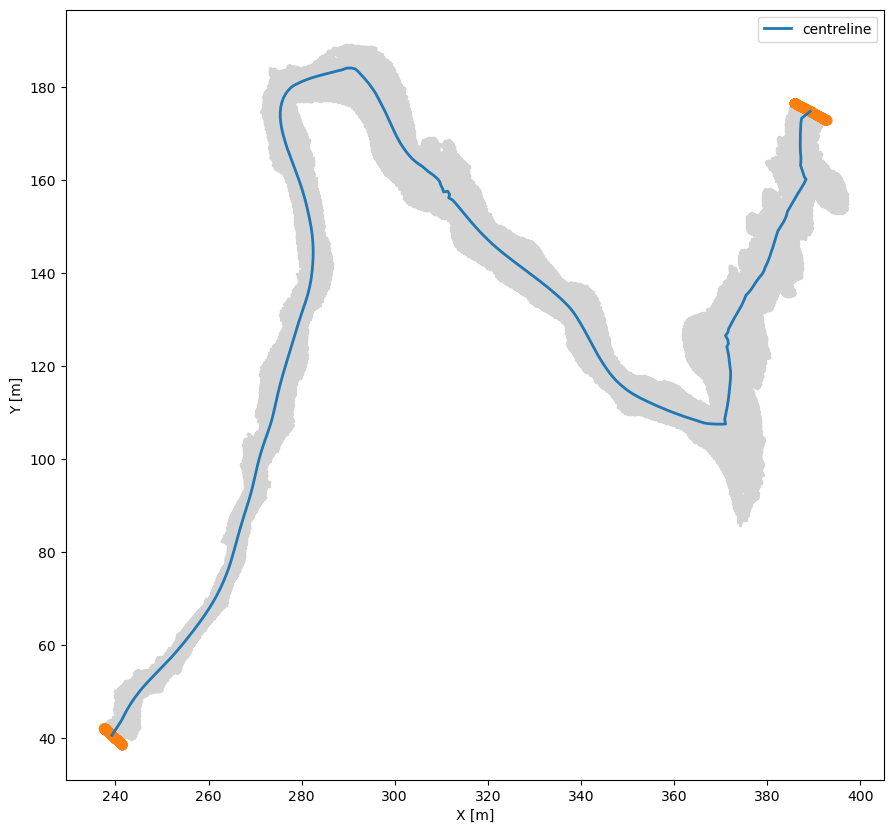

In [11]:
fig, ax = plt.subplots(figsize=(20, 10))

ax.scatter(*mesh_data[::100, [0,1]].T, color = "lightgrey", s = 2)

ax.plot(*centreline[:, [0,1]].T, zorder = 100, lw = 2, label = "centreline")
for key, value in rings.items():
    if "ring" in key:
        ax.scatter(*value[:, [0,1]].T, color="C1")
        
ax.set_aspect("equal")
ax.legend()
ax.set_ylabel("Y [m]")
ax.set_xlabel("X [m]")

Text(0.5, 0, 'X [m]')

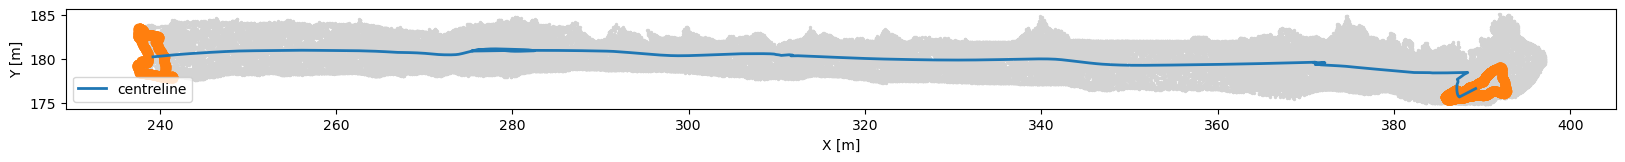

In [15]:
fig, ax = plt.subplots(figsize=(20, 10))

ax.scatter(*mesh_data[::100, [0,2]].T, color = "lightgrey", s = 2)

ax.plot(*centreline[:, [0,2]].T, zorder = 100, lw = 2, label = "centreline")
for key, value in rings.items():
    if "ring" in key:
        ax.scatter(*value[:, [0,2]].T, color="C1")
        
ax.set_aspect("equal")
ax.legend()
ax.set_ylabel("Y [m]")
ax.set_xlabel("X [m]")

In [16]:
sections = [mesh_intersect(mesh_data, P, nP) for P, nP in tqdm(zip(centreline[1:-1], normed_vectors), total=len(normed_vectors))]





















2it [01:03, 31.95s/it]








error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide


error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide


error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide


error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide


...

error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide


error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide


error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide


error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide
error found:  invalid value encountered in scalar divide

















100%|████████████████████████████████████████████████████████████████████████████████| 443/443 [13:42<00:00,  1.86s/it]


## Inspection of the generated sections

We look at the generated sections in plan view. 

Text(0.5, 0, 'X [m]')

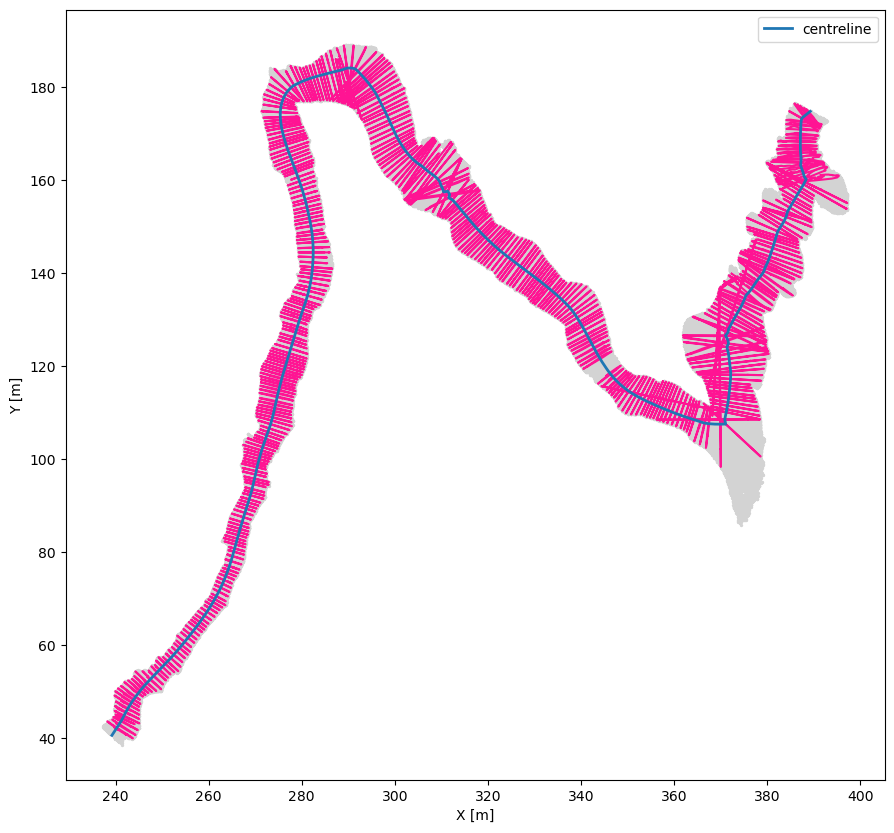

In [17]:
fig, ax = plt.subplots(figsize=(20, 10))

ax.scatter(*mesh_data[::100, [0,1]].T, color = "lightgrey", s = 2)

ax.plot(*centreline[:, [0,1]].T, zorder = 100, lw = 2, label = "centreline")

for section in sections[1:]:
    if section is not None:
        ax.plot(*section[0][:, [0,1]].T, color = "deeppink")

ax.set_aspect("equal")
ax.legend()
ax.set_ylabel("Y [m]")
ax.set_xlabel("X [m]")

#plt.savefig(f"./temp/{conduit_name}_plan_sections.pdf")

Text(0.5, 0, 'X [m]')

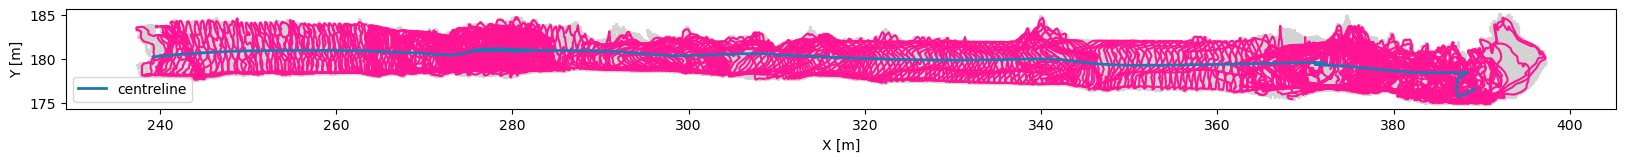

In [18]:
fig, ax = plt.subplots(figsize=(20, 10))

ax.scatter(*mesh_data[::100, [0,2]].T, color = "lightgrey", s = 2)

ax.plot(*centreline[:, [0,2]].T, zorder = 100, lw = 2, label = "centreline")
for section in sections:
    if section is not None:
        ax.plot(*section[0][:, [0,2]].T, color = "deeppink")

ax.set_aspect("equal")
ax.legend()
ax.set_ylabel("Y [m]")
ax.set_xlabel("X [m]")

In [19]:
sections2d = [geom.to2D(elem[0], elem[5]) for elem in sections if elem is not None]
curvilinear_coord_indices = [c for c, elem in enumerate(sections) if elem is not None]

In [20]:
# initialise a list of dictionaries 

descriptors = []

for section, curvilinear_coord in tqdm(zip(sections2d, curvilinear_coords[curvilinear_coord_indices]), total=len(sections2d)):
    try:
        description = geom.describe(section)
        description["curvilinear_coord"] = curvilinear_coord

        descriptors.append(description)
    except ValueError:
        pass

100%|████████████████████████████████████████████████████████████████████████████████| 443/443 [00:11<00:00, 37.23it/s]


In [ ]:
dhi = np.array([elem["hydraulic_diameter"] for elem in descriptors][1:])
li = np.diff(curvilinear_coords[curvilinear_coord_indices])

In [ ]:
def equivalent_dh(dhi, li):
    # harmonic mean along the section 
    return np.sum(li)**(1/4) * np.sum(li *dhi**(-4))**(-1/4)

In [ ]:

fig, (ax, axchords) = plt.subplots(2, 1, figsize = (8, 5))

ax.plot(curvilinear_coords[curvilinear_coord_indices][1:], dhi, "-o", markersize=4)


#plt.plot(curvilinear_coords[1:-1], [elem["hydraulic_diameter"] for elem in descriptors][1:], label = "hydraulic_diameter")
ax.axhline(equivalent_dh(dhi, li), ls = "-", xmin=0.05, xmax=0.95)

ax.text(1,equivalent_dh(dhi, li)*1.1, "eq. Dh section", color = "C0", fontsize = 8)

ax.set_xlabel("curvilinear coordinate [m]")
ax.set_ylabel("hydraulic diameter [m]")


axchords.plot(curvilinear_coords[curvilinear_coord_indices][1:], [elem["max_chord_length"] for elem in descriptors][1:], "-o", markersize=4)
axchords.set_xlabel("curvilinear coordinate [m]")
axchords.set_ylabel("longest chord [m]")

plt.tight_layout()
#plt.savefig(f"./temp/{conduit_name}_hydraulic_diameters.pdf")

In [ ]:
import pandas as pd

In [ ]:
descriptor_keys = [elem for elem in descriptors[0].keys() if elem != "cog" and elem !="ellipse_area" and elem !="ellipse_axes" and elem !="ellipse_eigenvalues"]
m = len(descriptors)
n = len(descriptor_keys)
data = np.zeros((m,n))

# cycle over each descriptor and store to numpy array. 
for c, key in enumerate(descriptor_keys):
    data[:, c] =  [elem[key] for elem in descriptors]

df = pd.DataFrame(data, columns=descriptor_keys)
df.to_csv(passages_fp[INDEX][:-4]+"_descriptors.csv")